# 01 · Estacionariedad y estructura de la serie

**Descargo metodológico:** este notebook describe desviaciones estocásticas y anomalías en indicadores financieros. No predice quiebras ni insolvencias bancarias.

Se analiza la serie de **mora** del banco seleccionado con el contraste ADF (hipótesis nula: raíz unitaria) y KPSS (hipótesis nula: estacionariedad), además de las funciones de autocorrelación ACF y PACF antes y después de diferenciar.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def raiz_proyecto():
    actual = Path.cwd()
    for base in [actual, *actual.parents]:
        if (base / "dashboard" / "data.json").exists():
            return base
    raise FileNotFoundError("Ejecute el notebook desde el repositorio del proyecto")

ROOT = raiz_proyecto()
datos = json.loads((ROOT / "dashboard" / "data.json").read_text(encoding="utf-8"))
BANCO = "bfort"
INDICADOR = "mora"
banco = next(b for b in datos["bancos"] if b["id"] == BANCO)
meta_indicador = next(i for i in datos["indicadores_meta"] if i["id"] == INDICADOR)
serie = datos["series"][BANCO][INDICADOR]
tabla = pd.DataFrame({
    "fecha": pd.to_datetime(serie["fechas"]),
    "valor": serie["observado"],
}).set_index("fecha")
tabla.head()

,valor
fecha,
2019-01-01,1.668071
2019-02-01,2.277313
2019-03-01,2.143988
2019-04-01,2.250342
2019-05-01,1.905817


## Identificación de la serie

In [2]:
print("Banco:", banco["nombre"])
print("Indicador:", meta_indicador["nombre"])
print("Observaciones:", len(tabla))
print("Rango:", tabla.index.min().strftime("%Y-%m"), "a", tabla.index.max().strftime("%Y-%m"))
print("Media:", round(float(tabla["valor"].mean()), 4))
print("Desviación estándar:", round(float(tabla["valor"].std()), 4))

Banco: Banco Fortaleza S.A.
Indicador: Índice de Morosidad
Observaciones: 84
Rango: 2019-01 a 2025-12
Media: 3.2229
Desviación estándar: 1.7727


## Serie observada

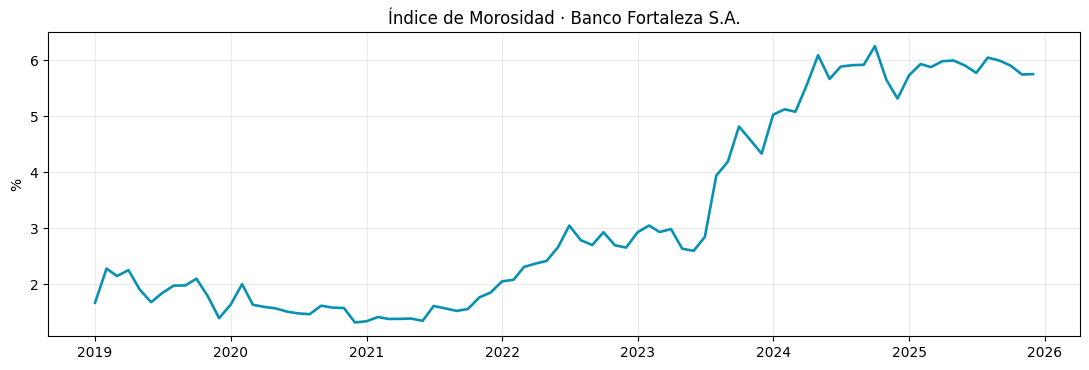

In [3]:
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(tabla.index, tabla["valor"], color="#0891b2", linewidth=1.9)
ax.set_title(f"{meta_indicador['nombre']} · {banco['nombre']}")
ax.set_ylabel("%")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Contrastes ADF y KPSS

In [4]:
e = serie["estacionariedad"]
resumen = pd.Series({
    "ADF estadístico": e["adf_stat"],
    "ADF p-valor": e["adf_pval"],
    "KPSS estadístico": e["kpss_stat"],
    "KPSS p-valor": e["kpss_pval"],
    "d recomendado": e["d_recomendado"],
    "D estacional": e["D_estacional"],
    "Veredicto": e["veredicto"],
})
display(resumen.to_frame("valor"))

,valor
ADF estadístico,-0.224837
ADF p-valor,0.935496
KPSS estadístico,1.29533
KPSS p-valor,0.01
d recomendado,1
D estacional,0
Veredicto,Raíz Unitaria Pura


La lectura debe hacerse en conjunto. En series cortas con estacionalidad marcada es frecuente que ADF y KPSS entreguen señales mixtas; el veredicto *Inconclusa* se reporta sin forzar una conclusión.

## ACF y PACF originales

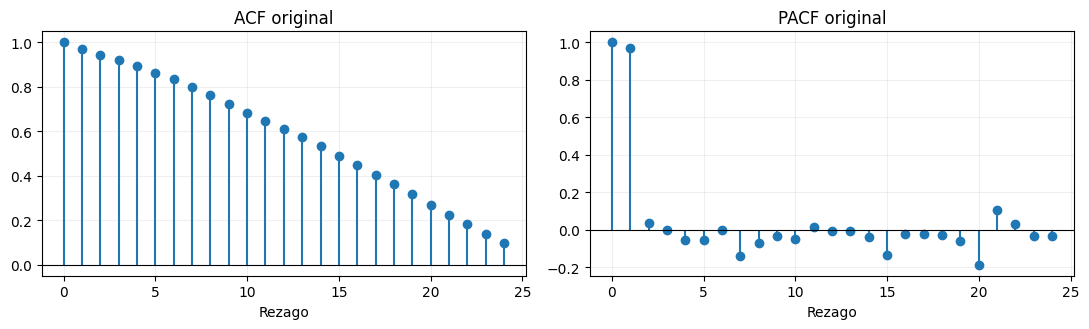

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
lags = np.arange(len(e["acf_orig"]))
axes[0].stem(lags, e["acf_orig"], basefmt=" ")
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_title("ACF original")
axes[0].set_xlabel("Rezago")
lags = np.arange(len(e["pacf_orig"]))
axes[1].stem(lags, e["pacf_orig"], basefmt=" ")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_title("PACF original")
axes[1].set_xlabel("Rezago")
for ax in axes:
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## ACF y PACF después de diferenciar

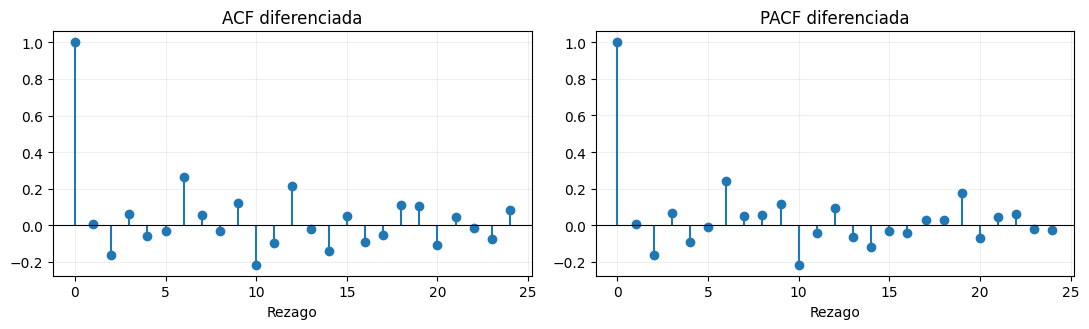

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
lags = np.arange(len(e["acf_diff"]))
axes[0].stem(lags, e["acf_diff"], basefmt=" ")
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_title("ACF diferenciada")
axes[0].set_xlabel("Rezago")
lags = np.arange(len(e["pacf_diff"]))
axes[1].stem(lags, e["pacf_diff"], basefmt=" ")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_title("PACF diferenciada")
axes[1].set_xlabel("Rezago")
for ax in axes:
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## Serie original y primera diferencia

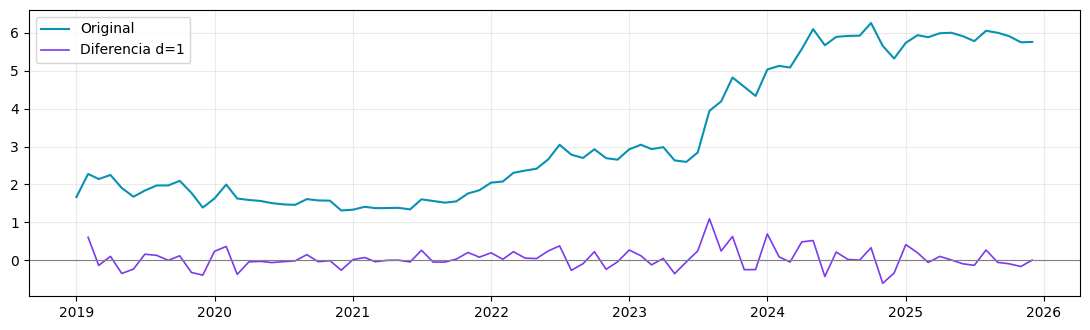

In [7]:
d = int(e["d_recomendado"])
diferenciada = tabla["valor"].diff(d).dropna()
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(tabla.index, tabla["valor"], color="#0891b2", linewidth=1.5, label="Original")
ax.plot(diferenciada.index, diferenciada, color="#7c3aed", linewidth=1.2, label=f"Diferencia d={d}")
ax.axhline(0, color="gray", linewidth=0.8)
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Lectura para la defensa

- El contraste ADF busca evidencia contra una raíz unitaria; el KPSS busca evidencia contra la estacionariedad.
- Un p-valor pequeño no mide la probabilidad de quiebra: solo indica incompatibilidad con la hipótesis nula del contraste.
- La diferenciación sugerida alimenta la grilla SARIMA, pero el orden final se elige por AIC/BIC y se valida con backtesting.